# Density Functional Theory (DFT) for an Atom

DFT is a quantum mechanical method used to investigate the electronic structure of many-body systems, particularly atoms, molecules, and solids. It simplifies the complex interactions between electrons by using functionals of the electron density rather than wavefunctions. 

In this exercise we will solve a multielectron atom in local density approximation (LDA). LDA is the simplest approximation in DFT, where the exchange-correlation energy is approximated by that of a homogeneous electron gas with the same local density.

We will test it on He and oxygen by computing the total energy and charge density.

We will plot charge density and compute the total energy, which will be compared to the reference data at NIST database:
https://www.nist.gov/pml/atomic-reference-data-electronic-structure-calculations/atomic-reference-data-electronic-7




We want to solve the Schrödinger equation for an atom with nucleus charge Z. We will approximate electron-electron interaction with an effective potential, which is computed by so-called "local density approximation" (LDA). In this theory, the classical (Hartree) potential is treated exactly, while the rest of the interaction is "approximated" by so called *local exchange-correlation functional*. We will not go into details of this functional, we will just use it here.



The Schrödinger equation we are solving is
\begin{align}
(-\frac{\hbar^2}{2m}\nabla^2-\frac{Z e^2}{4\pi\varepsilon_0 r} + V_H(r) + V_{xc}(r))\psi(\vec{r})=\varepsilon \psi(\vec{r})
\end{align}

The first two terms are appearing in Hydrogen problem, and we already coded them. The Hartree is the electrostatic potential, and the exchange-correlation potential has an approximate form, which depends only the charge density of the system. We will use the module `excor.py`, where the function $V_{xc}(\rho)$ is tabulated. We will use it as $V_{xc}(r) = V_{xc}(\rho(r))$, corresponding to the local density approximation.

Using atomic units, the equation is:
\begin{align}
\left(-\nabla^2-\frac{2Z}{r}+V_H(r)+V_{xc}(r)-\varepsilon\right)\psi(r)=0
\end{align}
and when spherical symmetry of an atom is taken into account:
\begin{align}
u''(r)-
\left(\frac{l(l+1)}{r^2}-\frac{2Z}{r}+V_H(r)+V_{xc}(r)-\varepsilon\right)u(r)=0
\end{align}


First we take the code from the Hydrogen project and repeat.

In [1]:
from scipy import integrate
from scipy import optimize
import numpy as np
from numpy.polynomial import Polynomial
import matplotlib.pyplot as plt
from numba import jit

In [2]:
@jit(nopython=True) # just-in-time compilation
def Numerov(f, x0, dx, dh):
    """ Given precumputed function f(x) solved the differential equation
        x''(t) = f(t) x(t)
        input: x0 = x(t=0), and dx = dx/dt(t=0)
    """
    x = np.zeros(len(f))
    x[0] = x0
    x[1] = x0 + dh*dx
    h2 = dh**2
    h12 = h2/12.
    w0 = x0*(1-h12*f[0])
    w1 = x[1]*(1-h12*f[1])
    xi = x[1]
    fi = f[1]
    for i in range(2,len(f)):
        w2 = 2*w1-w0 + h2*fi*xi
        fi = f[i]
        xi = w2/(1-h12*fi)
        x[i]=xi
        (w0,w1) = (w1,w2)
    return x

@jit(nopython=True)
def fShrod(En,l,R):
    return l*(l+1.)/R**2 - 2./R - En

def ComputeSchrod(En, R, l):
    f = fShrod(En,l,R[::-1])
    ur = Numerov(f, 0.0, -1e-7, -R[1]+R[0])[::-1]
    norm = integrate.simpson(ur**2, x=R)
    return ur/np.sqrt(np.abs(norm))
    
def Shoot(En, R, l):
    ur = ComputeSchrod(En, R, l)
    ur = ur/R**l  # expecting urn \propto R
    #f0,f1 = ur[0],ur[1]
    #f_at_0 = f0 + (f1-f0)*(0-R[0])/(R[1]-R[0]) # extrapolation to zero
    #return f_at_0
    #poly = np.polyfit(R[:4], ur[:4], deg=3)
    #return np.polyval(poly, 0.0)
    poly = Polynomial.fit(R[:4], ur[:4], deg=3)
    return poly(0.0)        

def FindBoundStates(R, l, nmax, Esearch):
    n=0
    Ebnd=[]
    u0 = Shoot(Esearch[0],R,l)
    for i in range(1,len(Esearch)):
        u1 = Shoot(Esearch[i],R,l)
        if u0*u1 < 0:
            #print 'Sign change at', Esearch[i-1], Esearch[i]
            Ebound = optimize.brentq(Shoot,Esearch[i-1],Esearch[i],xtol=1e-15,args=(R,l))
            Ebnd.append( (l,Ebound) )
            if len(Ebnd)>nmax: break
            n += 1
            print('Found bound state at E=%14.9f' % Ebound)
        u0 = u1
    return Ebnd 

def cmpKey(x):
    return x[1]*1000 + x[0]  # energy has large wait, but degenerate energy states are sorted by l

def ChargeDensity(Bnd,R,Z):
    rho = np.zeros(len(R))
    N=0.
    for (l,En) in Bnd:
        ur = ComputeSchrod(En, R, l)
        dN = 2*(2*l+1)
        if N+dN <= Z:
            ferm = 1.
        else:
            ferm = (Z-N)/float(dN)
        drho = ur**2 * ferm * dN/(4*np.pi*R**2)
        rho += drho
        N += dN
        print('adding state', (l,En), 'with fermi=', ferm)
        if  N>=Z: break
    return rho

Found bound state at E=  -0.999999943
Found bound state at E=  -0.249999990
Found bound state at E=  -0.111111108
Found bound state at E=  -0.062499999
Found bound state at E=  -0.039999942
Found bound state at E=  -0.249999998
Found bound state at E=  -0.111111111
Found bound state at E=  -0.062500000
Found bound state at E=  -0.039999957
Found bound state at E=  -0.111111111
Found bound state at E=  -0.062500000
Found bound state at E=  -0.039999977
Found bound state at E=  -0.062500000
Found bound state at E=  -0.039999992
adding state (0, -0.9999999428188766) with fermi= 1.0
adding state (0, -0.24999998998162612) with fermi= 1.0
adding state (1, -0.2499999979714585) with fermi= 1.0
adding state (0, -0.11111110835536737) with fermi= 1.0
adding state (1, -0.1111111105768176) with fermi= 1.0
adding state (2, -0.1111111111469023) with fermi= 1.0


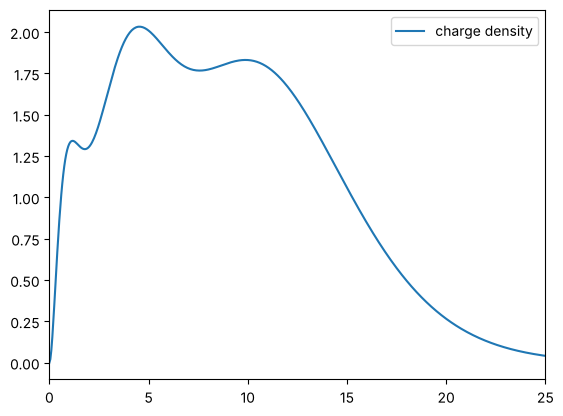

In [3]:
%matplotlib inline

Esearch = -1.2/np.arange(1,20,0.2)**2
R = np.linspace(1e-6,100,2000)

nmax = 5
Bnd=[]
for l in range(nmax-1):
    Bnd += FindBoundStates(R,l,nmax-l,Esearch)
Bnd = sorted(Bnd, key=cmpKey)

Z=28
rho = ChargeDensity(Bnd,R,Z)
        
plt.plot(R, rho*(4*np.pi*R**2), label='charge density')
plt.xlim([0,25])
plt.legend(loc='best')
plt.show()

## Hartree term

The Hartree term is treated exactly in this approximation. 

It describes the electrostatic
interaction of one electron with the cloud of all electrons (including the electron itself).

This is classical electrostatic term. Namely, any electron feels not only the nucleus with Coulomb attraction $-2Z/r$, but also the charge of all (other) electrons $\rho(\vec{r}')$ through the same Coulomb force, but it is repulsive, hence we should have $$-2Z/r \rightarrow -2Z/r + \int d\vec{r}' \frac{2\rho(\vec{r}')}{|\vec{r}-\vec{r}'|}$$


Mathematically, this term comes from the mean-field approximation (lowest order) of the Coulomb repulsion between electrons:

\begin{align}
&&   \frac{1}{2}\int d\vec{r} d\vec{r}' \psi^\dagger (\vec{r})\psi^\dagger (\vec{r}')
   v_c(\vec{r}-\vec{r}') \psi(\vec{r}')\psi(\vec{r}) \rightarrow\\
&&   \int d\vec{r} \psi^\dagger(\vec{r}) \psi(\vec{r}) \int d\vec{r}'
   \langle\psi^\dagger(\vec{r}') \psi(\vec{r}')\rangle v_c(\vec{r}-\vec{r}') \equiv
   \int d\vec{r} \psi^\dagger(\vec{r}) V_{H}(\vec{r}) \psi(\vec{r})\nonumber
 \end{align}
 with

 \begin{equation}
 V_H(\vec{r}) = 2 \int d\vec{r}' \frac{\rho(\vec{r}')}{|\vec{r}-\vec{r}'|}
 \end{equation}

where $2$ is due to Rydberg units since $v_c = 2/r$.


For any atom, the electron density is
spherically symmetric and hence $V_{H}$ depends only on radial
distance. (In solids, the hartree potential should be expanded in
spheric harmonics to sufficiently high $l$, maybe $l=6$).


### Step 1: Using $\rho(r)$, compute the Hartree potential.

This is usually achieved by solving the Poisson equation. From
classical electrostatic we know
\begin{align}
  \nabla^2 V_{H}(\vec{r}) = -8\pi \rho(\vec{r})
\end{align}
If we express $\nabla$ in spherical coordinates, we get:
\begin{equation}
\frac{1}{r^2}\frac{d}{dr}(r^2 \frac{d V_H}{dr})= -8\pi\rho(r)  
\end{equation}
which simplifies to
\begin{equation}
  U^{''}(r) = -8\pi r \rho(r)
\end{equation}
where $V_{H}(r) = U(r)/r$.

This second order differential equation has the following boundary
conditions $U(0)=0$ and $U(\infty)=2 Z$.

The two point boundary problem does not require shooting because we
know solution to the homogenous differential equation
$U^{''}(r)=0$. The Hartree potential can be obtained from any
particular solution by
\begin{equation}
  U(r) = U_p(r) + \alpha r
\end{equation}
where $\alpha = \lim_{r\rightarrow\infty}(2 Z-U_{p}(r))/r$.


In [4]:
def FuncForHartree(y,r,rhoSpline):
    """ y = [U,U']
        dy/dr = [U', -8*pi*r*rho(r)]
    """
    return [y[1], -8*np.pi*r*rhoSpline(r)]

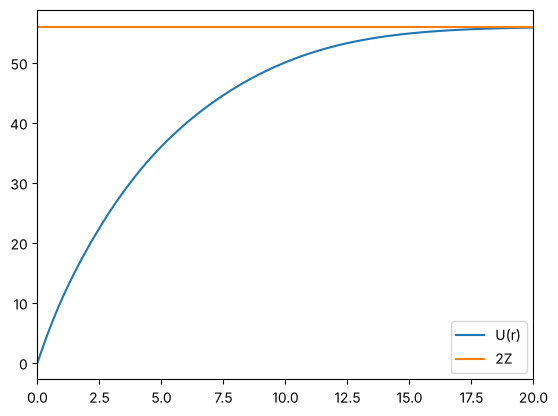

In [5]:
from scipy import interpolate

rhoSpline = interpolate.UnivariateSpline(R, rho, s=0)

U0 = integrate.odeint(FuncForHartree, [0.0,0.5], R, args=(rhoSpline,))[:,0]
alpha = (2*Z - U0[-1])/R[-1]
U0 += alpha * R

plt.plot(R, U0,label='U(r)')
plt.plot(R, np.ones(len(R))*2*Z, label='2Z')
plt.xlim([0,20])
plt.legend(loc='best')
plt.show()

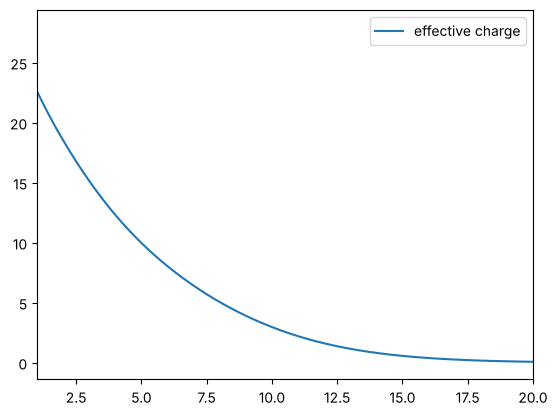

In [6]:
plt.plot(R, Z-U0/2,label='effective charge')
plt.xlim([1,20])
plt.legend(loc='best')
plt.show()

## Numerov again

Poisson equation does not have the first order derivative, hence it can also be more efficiently solved by the Numerov algorithm.

We have Poisson equation, which has the form
\begin{equation}
x^{''}(t)= u(t)
\end{equation}
and the Numerov algorithm, as appropriate for the Poisson equation, is

\begin{align}
  x(h)+x(-h) = 2x(0)+h^2 u(0)+\frac{2}{4!}h^4 x^{(4)}(0)+O(h^6)
\end{align}

and the approximation for the forth order derivative is
\begin{equation}
  x^{(4)}\sim \frac{u_{i+1}-2 u_i+u_{i-1}}{h^2}
\end{equation}

Inserting the fourth order derivative into the above recursive equation (forth equation in his chapter), we
get

\begin{equation}
  x_{i+1}-2 x_i+x_{i-1}=h^2 u_i +\frac{h^2}{12}(u_{i+1}-2 u_i+u_{i-1})
\end{equation}

If we switch to a new variable $w_i=x_i-\frac{h^2}{12}u_i$
we are left with the following
equation

\begin{equation}
  w_{i+1} -2 w_i + w_{i-1} = h^2 u_i+O(h^6)
\end{equation}

The variable $x$ needs to be recomputed at each step with
$x_i=(w_i+\frac{h^2}{12}u_i)$.


In [7]:
@jit(nopython=True)
def NumerovUP(U, x0, dx, dh):
    x = np.zeros(len(U))
    x[0] = x0
    x[1] = dx*dh + x0
    h2 = dh*dh
    h12 = h2/12
    w0 = x[0]-h12*U[0]
    w1 = x[1]-h12*U[1]
    Ui = U[1]
    for i in range(2,len(U)):
        w2 = 2*w1 - w0 + h2*Ui
        Ui = U[i]
        xi = w2 + h12*Ui
        x[i] = xi
        w0, w1 = w1, w2
    return x

In [8]:
U2 = NumerovUP(-8*np.pi*R*rho, 0.0, 0.5, R[1]-R[0])
alpha2 = (2*Z-U2[-1])/R[-1]
U2 += alpha2 * R

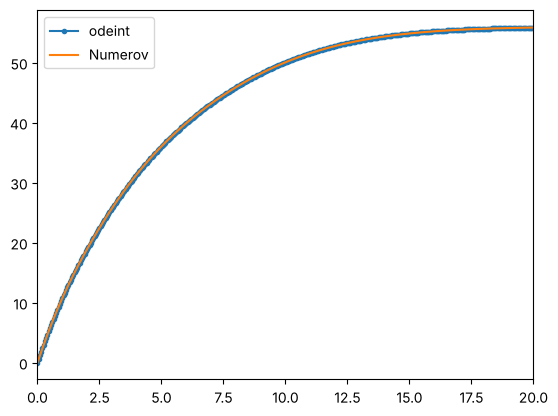

In [9]:
plt.plot(R,U0,'.-',label='odeint')
plt.plot(R,U2,'-',label='Numerov')
plt.xlim([0,20])
plt.legend(loc='best')
plt.show()

### Step1 routine HartreeU  
For generic density the following routine will work:

In [10]:
def HartreeU(R, rho, Zatom):
    """Given input charge density it returns Hartree potential in the form VH(r)*r
    """
    U2 = NumerovUP(-8*np.pi*R*rho, 0.0, 0.5, R[1]-R[0])
    alpha2 = (2*Zatom-U2[-1])/R[-1]
    U2 += alpha2 * R
    return U2

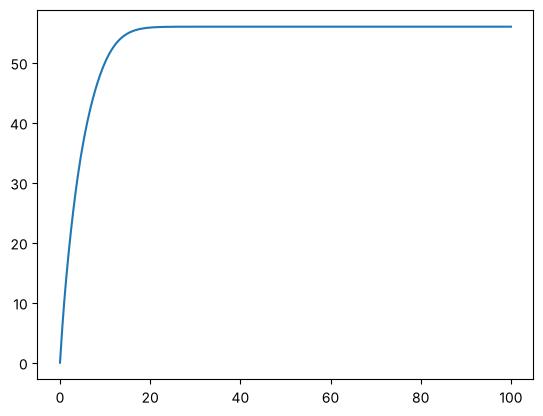

In [11]:
U2 = HartreeU(R,rho,Z)
plt.plot(R,U2)
plt.show()

### Step 2 : Compute the exchange correlation potential.
   
Note that $V_{xc}(r)=V_{xc}(\rho(r))$ is unquely determined by the electron charge density $\rho(r)$. If we know $\rho$, we can instantly compute $V_{xc}$ by the module provided parametrized function.
   

The module `excor.py` is from http://www.physics.rutgers.edu/~haule/509/src_prog/python/homework5

Instantiate the ExchangeCorrelation object by

`exc = ExchangeCorrelation()`

and used it, for example, by

`exc.Vx(rs(rho[i]))+exc.Vc(rs(rho[i]))`

where $r_s = ({4\pi\rho/3})^{-1/3}$.

Be careful: The energy unit in "excor.py" is Hartree and not
Rydergs. Hence, you need to multiply energy or potential by 2.



In [12]:
from excor import ExchangeCorrelation
exc = ExchangeCorrelation()

@jit(nopython=True)
def rs(rho):
    "1/rho = 4*pi*rs^3/3 => rs = (3/(4*pi*rho))**(1/3.)"
    if rho < 1e-100: return 1e100
    return pow(3/(4*np.pi*rho),1/3.)

### Step 3: Find bound states using Hartree and XC potential.

Add the Hartree potential and the exchange-correlation potential to the Schrödinger equation and find
  bound states of the atom.

The Schrödinger equation is

 \begin{equation}
   u^{''}(r) = \left(\frac{l(l+1)}{r^2}-\frac{2 Z}{r} + V_{H}(r)+V_{XC}(r)-\varepsilon\right)u(r).
 \end{equation}

or

  \begin{equation}
   u^{''}(r) = \left(\frac{l(l+1)}{r^2}+\frac{U_H - 2 Z +r V_{XC}}{r}-\varepsilon\right)u(r).
 \end{equation}

 
 We will use notation:
 $$U_{KS}=U_H - 2 Z +r V_{XC}$$
 so that

   \begin{equation}
   u^{''}(r) = \left(\frac{l(l+1)}{r^2}+\frac{U_{KS}}{r}-\varepsilon\right)u(r).
 \end{equation}


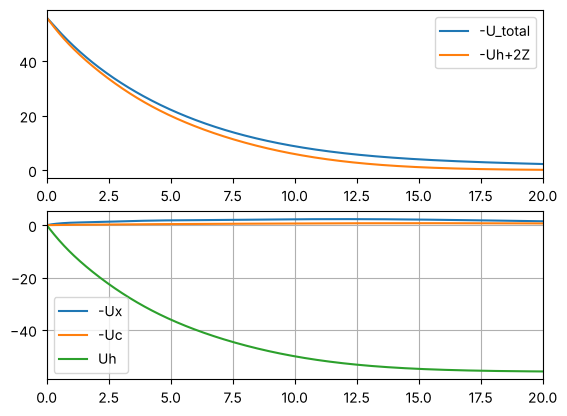

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming exc, rs, rho, R, U2, and Z are defined earlier in the code

Vxc = np.array([2*exc.Vc(rs(rh)) + 2*exc.Vx(rs(rh)) for rh in rho])    # factor of 2 due to change of units from Hartree to Rydbers
Vx = np.array([2*exc.Vx(rs(rh)) for rh in rho])  
Vc = np.array([2*exc.Vc(rs(rh)) for rh in rho])
Uks = U2 - 2*Z + Vxc*R

fig,(ax1, ax2) = plt.subplots(2, 1)
ax1.plot(R, -Uks, label='-U_total');
ax1.plot(R, -U2+2*Z, label='-Uh+2Z')
#ax1.plot(R, -U2+2*Z, label='-Uh+2Z')
ax2.plot(R,-Vx*R,label='-Ux')
ax2.plot(R,-Vc*R,label='-Uc')
ax2.plot(R,-U2,label='Uh')
ax2.legend(loc='best')
ax1.legend(loc='best')
ax2.grid()
ax1.set_xlim([0,20])
ax2.set_xlim([0,20])
plt.show()

The effective potential $U_{KS} = r(V_H+V_{xc}-2 Z/r)$ has the following features:
* at small $r$ it is just bare nucleus potential $U_{KS}=-2 Z$ because $V_{KS}=-2 Z/r$
* at large $r$ the screening of nuclear charge is perfect, and $U_{KS}=0$ exponentially fast beyond the charge cloud, hence $U_{KS}\approx 2(\rho_{inside}-Z)$ vanishes exponentially.

In [14]:
@jit(nopython=True)
def fShrod(En,l,R, Uks):
    return (l*(l+1.)/R +Uks)/R - En

def ComputeSchrod(En, R, l, Uks):
    #f = fShrod(En,l,R[::-1],Uks[::-1])
    #ur = Numerov(f, 0.0, -1e-10, R[0]-R[1])[::-1]
    f = fShrod(En,l,R, Uks)
    ur = Numerov(f[::-1], 0.0, -1e-10, R[0]-R[1])[::-1]
    norm = integrate.simpson(ur**2, x=R)
    return ur/np.sqrt(np.abs(norm))

def Shoot(En, R, l, Uks):
    ur = ComputeSchrod(En, R, l,Uks)
    ur *= 1/R**l  # expecting urn \propto R
    #f0,f1 = ur[0],ur[1]
    #f_at_0 = f0 + (f1-f0)*(0-R[0])/(R[1]-R[0]) # extrapolation to zero
    #return f_at_0
    poly = Polynomial.fit(R[:4], ur[:4], deg=3)
    #poly = Polynomial.fit(R[:2], ur[:2], deg=1)
    return poly(0.0)

In [15]:
def FindBoundStates(R, l, nmax, Esearch, Uks, silent=False):
    n=0
    Ebnd=[]
    u0 = Shoot(Esearch[0],R,l,Uks)
    for i in range(1,len(Esearch)):
        u1 = Shoot(Esearch[i],R,l,Uks)
        if u0*u1 < 0:
            Ebound = optimize.brentq(Shoot,Esearch[i-1],Esearch[i],xtol=1e-15,args=(R,l,Uks))
            Ebnd.append( (l,Ebound) )
            if len(Ebnd)>nmax: break
            n += 1
            if not silent:
                print(f"Found bound state at E={Ebound/2:14.9f}H l={l:2d}")
        u0 = u1
    return Ebnd 

In [16]:
## From before we are using
# R = linspace(1e-6,100,2000)
# Esearch = -1.2/arange(1,20,0.2)**2
nmax=5

Bnd=[]
for l in range(nmax-1):
    Bnd += FindBoundStates(R,l,nmax-l,Esearch,Uks)
    
Bnd = sorted(Bnd, key=cmpKey)

Found bound state at E=  -0.301181700H l= 0
Found bound state at E=  -0.114301424H l= 0
Found bound state at E=  -0.034082204H l= 0
Found bound state at E=  -0.003612354H l= 0
Found bound state at E=  -0.313798778H l= 1
Found bound state at E=  -0.118616033H l= 1
Found bound state at E=  -0.034746947H l= 1
Found bound state at E=  -0.003345161H l= 1
Found bound state at E=  -0.300009838H l= 2
Found bound state at E=  -0.108653489H l= 2
Found bound state at E=  -0.028845107H l= 2


Found bound state at E=  -0.279116709H l= 3
Found bound state at E=  -0.093722034H l= 3


### Step 4: Compute the new electron density
by filling the lowest $Z$ eigenstates.

In [17]:
# This is modified from Hydrogen
def ChargeDensity(bst,R,Zatom,Uks,silent=False):
    rho = np.zeros(len(R))
    N=0.
    Ebs=0.  # sum of all eigenvalues of KS equation.
    for (l,En) in bst:
        ur = ComputeSchrod(En, R, l, Uks)
        dN = 2*(2*l+1)
        if N+dN <= Zatom:
            ferm = 1.
        else:
            ferm = (Zatom-N)/float(dN)
        drho = ur**2 * ferm * dN/(4*np.pi*R**2)
        rho += drho
        N += dN
        Ebs += En * dN * ferm
        if not silent:
            print('adding state', (l,En/2,dN), ' with fermi=', ferm)
        if  N>=Zatom: break
    return (rho,Ebs)

In [18]:
Z=28 
# 1s2 
# 2s2 2p6
# 3s2 3p6 3d8
# 4s2 
rho_new, Ebs = ChargeDensity(Bnd,R,Z,Uks)

adding state (1, -0.31379877794652333, 6)  with fermi= 1.0
adding state (0, -0.30118170042728976, 2)  with fermi= 1.0
adding state (2, -0.3000098384118069, 10)  with fermi= 1.0
adding state (3, -0.2791167088439725, 14)  with fermi= 0.7142857142857143


### Step 5: Admix the new and the old density 
(50\% of the old and 50\%  of the new should work) and use the resulting density to compute the  new Hartree and exchange-correlation potential.

### Iterate Steps 1 to Step 5 until self-consistency is achieved.

### Evaluate the total energy

Once we see that the code converges, we can insert a new step
between *Step 4* and *Step 5* to compute the total energy of
the system. The total energy can be obtained by
\begin{align}
E^{LDA}_{total} =& \sum_{i\in occupied}\int d\vec{r}
\psi_i^*(\vec{r})[-\nabla^2]\psi_i(\vec{r}) +\nonumber\\
 &+ \int d\vec{r} \rho(\vec{r}) [V_{nucleus}(\vec{r})+\epsilon_H(\vec{r}) +
   \epsilon_{XC}(\vec{r})]\nonumber\\
 =& \sum_{i\in occupied}\int d\vec{r}
\psi_i^*(\vec{r})[-\nabla^2+V_{nucleus}+V_H+V_{XC}]\psi_i(\vec{r})
 \nonumber\\
 &+ \int d\vec{r} \rho(\vec{r}) [\epsilon_H(\vec{r})-V_H(\vec{r}) +
   \epsilon_{XC}(\vec{r})-V_{XC}(\vec{r})]\nonumber\\
 =& \sum_{i\in occupied}\epsilon_i + \int d\vec{r} \rho(\vec{r}) [\epsilon_H(\vec{r})-V_H(\vec{r}) +
   \epsilon_{XC}(\vec{r})-V_{XC}(\vec{r})]\nonumber\\
 =& \sum_{i\in occupied}\epsilon_i + \int d\vec{r} \rho(\vec{r}) [-\epsilon_H(\vec{r}) +
   \epsilon_{XC}(\vec{r})-V_{XC}(\vec{r})]
\end{align}
Here we used
\begin{align}
&& E_H[\rho] \equiv \int d\vec{r}\; \rho(\vec{r})\; \epsilon_H[\rho(\vec{r})]\\
&& E_{xc}[\rho] \equiv \int d\vec{r}\; \rho(\vec{r})\; \epsilon_{xc}[\rho(\vec{r})]\\
&& V_H[\rho]\equiv \frac{\delta E_H[\rho]}{\delta \rho(\vec{r})}\\
&& V_{xc}[\rho]\equiv \frac{\delta E_{xc}[\rho]}{\delta \rho(\vec{r})}.
\end{align}

Here the Hartree energy is the classical electrostatic potential energy, i.e.,
\begin{equation}
E_H = \int d\vec{r} d\vec{r}' \frac{\rho(\vec{r})\rho(\vec{r}')}{|\vec{r}-\vec{r}'|},
\end{equation}
hence
\begin{align}
\epsilon_H(\vec{r}) = \frac{1}{2} V_H(\vec{r}) = \int d\vec{r}' \frac{\rho(\vec{r}')}{|\vec{r}-\vec{r}'|}\\
\end{align}
and we also know
\begin{align}
V_H(\vec{r})= \frac{U_H(\vec{r})}{r}
\end{align}
Hence
$$\epsilon_H(\vec{r})=\frac{1}{2}\frac{U_H}{r}$$


The exchange-correlation energy can be obtained by a call to the
 method of ${ExchangeCorrelation}$ object.


For oxygen, the total energy in this implementation is : -74.4730769 Hartree, while NIST shows -74.473077 Hartree. This is in excellent agreement in all digits provided by NIST. 

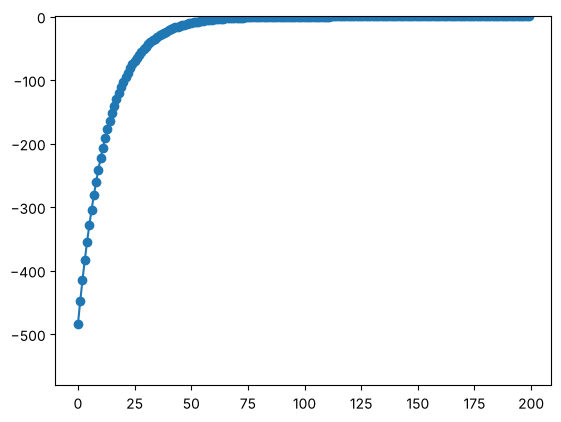

In [19]:
import numpy as np
import matplotlib.pyplot as plt

Zatom=22
E0=-1.0*Zatom**2
Eshift=0.1 # sometimes energies can be positive!!!                                                                                                                        
Esearch = -np.logspace(-4,np.log10(-E0+Eshift),200)[::-1] + Eshift
#Esearch = -np.logspace(-4,np.log10(-E0+Eshift),500)[::-1] + Eshift
plt.plot(Esearch,'o-')
plt.ylim([-1.2*Zatom**2,1])
plt.show()

#plt.ylim([-0.2,0.])

We will first demonstrate algorithm on oxygen $Z=8$ and then on Potassium ($Z=19$), which has first nontrivial "aufbau" principle in which $4s$ orbital gets filled before $3d$.

Iteration 0 Etot[Ry]= -2612.9346614125043 Etot[Hartree]= -1306.4673307062521 Diff= 2612.9346614125043


Iteration 1 Etot[Ry]= -953.777409319674 Etot[Hartree]= -476.888704659837 Diff= 1659.1572520928303


Iteration 2 Etot[Ry]= -1202.0239503598043 Etot[Hartree]= -601.0119751799022 Diff= 248.2465410401303


Iteration 3 Etot[Ry]= -1198.8767760205426 Etot[Hartree]= -599.4383880102713 Diff= 3.14717433926171


Iteration 4 Etot[Ry]= -1194.1262294933003 Etot[Hartree]= -597.0631147466502 Diff= 4.75054652724225


Iteration 5 Etot[Ry]= -1196.5057043289428 Etot[Hartree]= -598.2528521644714 Diff= 2.3794748356424407


... (21 outputs left out)

Iteration 27 Etot[Ry]= -1196.3920699775344 Etot[Hartree]= -598.1960349887672 Diff= 6.697746357531287e-07


Iteration 28 Etot[Ry]= -1196.392070386667 Etot[Hartree]= -598.1960351933335 Diff= 4.091325536137447e-07


Iteration 29 Etot[Ry]= -1196.3920705824335 Etot[Hartree]= -598.1960352912167 Diff= 1.9576646081986837e-07


Iteration 30 Etot[Ry]= -1196.3920706371782 Etot[Hartree]= -598.1960353185891 Diff= 5.474475983646698e-08


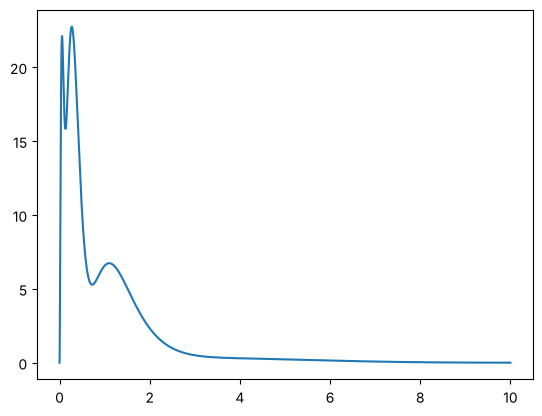

In [20]:
Zatom = 19
# 
R = np.linspace(1e-8,10,2**14+1)
mixr = 0.5

E0=-1.2*Zatom**2
Eshift=0.1 # sometimes energies can be positive!!!                                                                                                                        
Esearch = -np.logspace(-4,np.log10(-E0+Eshift),500)[::-1] + Eshift
nmax = 4 #3

exc = ExchangeCorrelation()
Uks = -2*Zatom*np.ones(len(R))  # here I changed from -2 to -2*Zatom
Eold = 0
Etol = 1e-7

# SCF loop
for itt in range(100):
    Bnd=[]
    for l in range(nmax-1):
        Bnd += FindBoundStates(R,l,nmax-l,Esearch,Uks, silent=True)
    
    Bnd = sorted(Bnd, key=cmpKey)
    rho_new, Ebs = ChargeDensity(Bnd,R,Zatom,Uks, silent=True)
    
    if itt==0:
        rho = rho_new
    else:
        rho = rho_new * mixr + (1-mixr)*rho_old
    rho_old = np.copy(rho)
    
    U2 = HartreeU(R, rho, Zatom)

    Vxc = [2*exc.Vc(rs(rh)) + 2*exc.Vx(rs(rh)) for rh in rho]   
    
    Uks = U2 - 2*Zatom + Vxc*R

    # Total energy
    ExcVxc = [2*exc.EcVc(rs(rh)) + 2*exc.ExVx(rs(rh)) for rh in rho]  # eps_xc(rho)-V_xc(rho)
    pot = (ExcVxc*R - 0.5*U2)*R*rho*4*np.pi                              # (eps_xc-V_xc-0.5 U_H/R)*rho * d^3r
    epot = integrate.simpson(pot, x=R)
    Etot = epot + Ebs
    
    # print('Total density has weight', integrate.simpson(rho*(4*np.pi*R**2),x=R))
    #print('Total Energy=', Etot/2.)
    
    print('Iteration', itt, 'Etot[Ry]=', Etot, 'Etot[Hartree]=', Etot/2, 'Diff=', np.abs(Etot-Eold))

    
    if  itt>0 and np.abs(Etot-Eold)< Etol: break
    Eold = Etot
    
    #plt.plot(R, U2, label='U-hartree')
    #plt.plot(R, Vxc, label='Vxc')
    #plt.plot(R, Uks, label='Uks')
    #plt.show()
    
plt.plot(R,rho*(4*np.pi*R**2))
#plt.xlim([0,5])
plt.show()

# Examples: the LDA code across the periodic table

The code above solves one atom. Below, the same algorithm is packaged into one
function and run for H–Kr, Xe and Rn: Numerov shooting for the radial
Kohn–Sham equation, the Hartree potential from the Poisson equation, LDA
exchange-correlation from `excor.py`, and linear density mixing.

Changes from the class version:

* The SCF loop is one function, `lda_atom(Z, config)`. It returns energies,
  eigenvalues, the density and the potential.
* The occupations are fixed by a configuration such as `'[Ar] 3d^10 4s^1'`.
  Ions are allowed. The NIST reference calculations use the same
  configurations, so the results can be compared one to one.
* `shoot` does not normalize $u(r)$, because only the sign of $u(0)$ matters.
  It rescales $u$ during the inward integration: deep core states grow by
  $e^{\kappa R_{max}}$ in the forbidden region and would overflow on a 20 bohr box.
* $V_{xc}(r_s)$ from `excor.py` is tabulated once on a logarithmic $r_s$ grid and
  interpolated.
* The SCF starts from a screened Coulomb potential instead of the bare nucleus.
* The box is $R_{max}=20$ bohr with $2^{14}+1$ points.

The code works in Rydberg units, as in class. Printed and plotted energies are
in Hartree or eV.

In [21]:
import time
from scipy.interpolate import CubicSpline
from scipy.special import eval_legendre

plt.rcParams.update({
    'font.family': 'serif', 'mathtext.fontset': 'dejavuserif', 'font.size': 11,
    'axes.linewidth': 0.8, 'lines.linewidth': 1.4,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'legend.frameon': False, 'figure.dpi': 110,
})
Ha_eV = 27.211386

In [22]:
exc = ExchangeCorrelation()
LNAME = 'spdf'


@jit(nopython=True)
def radial_inward(En, l, R, Uks):
    """Numerov for u'' = [l(l+1)/r^2 + U_KS/r - E] u from R_max inward (Ry).

    Same recursion as Numerov() above, started with u(R_max) = 0.
    u is rescaled whenever it exceeds 1e100."""
    n = len(R)
    h = R[1] - R[0]
    h12 = h*h/12.0
    f = (l*(l + 1.0)/R + Uks)/R - En
    u = np.zeros(n)
    u[n-2] = 1e-10*h
    w0 = 0.0
    w1 = u[n-2]*(1 - h12*f[n-2])
    for i in range(n-3, -1, -1):
        w2 = 2*w1 - w0 + h*h*f[i+1]*u[i+1]
        u[i] = w2/(1 - h12*f[i])
        w0, w1 = w1, w2
        if abs(u[i]) > 1e100:
            for k in range(i, n):
                u[k] *= 1e-100
            w0 *= 1e-100
            w1 *= 1e-100
    return u


@jit(nopython=True)
def shoot(En, l, R, Uks):
    """u(r)/r^l extrapolated to r = 0 by the cubic through the first 4 points."""
    u = radial_inward(En, l, R, Uks)
    s = 0.0
    for i in range(4):
        p = u[i]/R[i]**l
        for j in range(4):
            if j != i:
                p *= R[j]/(R[j] - R[i])
        s += p
    return s


def radial_function(En, l, R, Uks):
    """Normalized u_nl(r) = r R_nl(r)."""
    u = radial_inward(En, l, R, Uks)
    return u/np.sqrt(integrate.simpson(u**2, x=R))


def bound_states(l, nstates, R, Uks, Esearch):
    """Lowest `nstates` eigenvalues (Ry) with angular momentum l."""
    E = []
    u0 = shoot(Esearch[0], l, R, Uks)
    for i in range(1, len(Esearch)):
        u1 = shoot(Esearch[i], l, R, Uks)
        if u0*u1 < 0:
            E.append(optimize.brentq(shoot, Esearch[i-1], Esearch[i],
                                     xtol=1e-14, args=(l, R, Uks)))
            if len(E) == nstates:
                break
        u0 = u1
    return E


# excor.py tabulated once on a log(r_s) grid (Ry)
_lrs = np.linspace(np.log(1e-6), np.log(1e8), 4001)
_vxc = CubicSpline(_lrs, [2*(exc.Vx(x) + exc.Vc(x)) for x in np.exp(_lrs)])
_emv = CubicSpline(_lrs, [2*(exc.ExVx(x) + exc.EcVc(x)) for x in np.exp(_lrs)])


def xc_potential(rho):
    """V_xc(rho) and eps_xc(rho) - V_xc(rho) on the grid (Ry)."""
    lrs = np.log(3/(4*np.pi))/3 - np.log(np.maximum(rho, 1e-300))/3
    vacuum = lrs > _lrs[-1]                      # r_s > 1e8
    lrs = np.clip(lrs, _lrs[0], _lrs[-1])
    return np.where(vacuum, 0, _vxc(lrs)), np.where(vacuum, 0, _emv(lrs))

In [23]:
CORE = {'[He]': '1s^2', '[Ne]': '1s^2 2s^2 2p^6',
        '[Ar]': '1s^2 2s^2 2p^6 3s^2 3p^6'}
CORE['[Kr]'] = CORE['[Ar]'] + ' 3d^10 4s^2 4p^6'
CORE['[Xe]'] = CORE['[Kr]'] + ' 4d^10 5s^2 5p^6'


def parse_config(text):
    """'[Ne] 3s^2 3p^1' -> {(1,0): 2, (2,0): 2, (2,1): 6, (3,0): 2, (3,1): 1}"""
    for core, shells in CORE.items():
        text = text.replace(core, shells)
    occ = {}
    for shell in text.split():
        nl, q = shell.split('^')
        occ[(int(nl[0]), LNAME.index(nl[1]))] = float(q)
    return occ


def lda_atom(Z, config, Rmax=20.0, N=2**14+1, mix=0.5, Etol=1e-7,
             maxiter=300, Uks0=None, verbose=False):
    """Self-consistent LDA for a spherical atom or ion with fixed occupations.

    Z: nuclear charge. config: e.g. '[Ar] 3d^10 4s^1'.
    Returns a dict. Energies are in Hartree; R, rho, Uks, UH as in class."""
    occ = parse_config(config)
    Nel = sum(occ.values())
    lmax = max(max(l for n, l in occ), 1 if Z > 2 else 0, 2 if Z > 18 else 0)
    # one state above the highest occupied one for each l (if it is bound)
    nwant = {l: max([n for n, ll in occ if ll == l], default=l) - l + 1
             for l in range(lmax + 1)}
    R = np.linspace(1e-8, Rmax, N)
    Esearch = -np.logspace(-5, np.log10(1.3*Z**2), 300)[::-1]

    if Uks0 is None:   # screened Coulomb: charge Z at r = 0, Z - Nel + 1 far away
        Uks = -2*((Z - Nel + 1) + (Nel - 1)*np.exp(-R*Z**(1/3)/0.885))
    else:
        Uks = Uks0.copy()
    rho_old, Eold, hist, eps_hist = None, 0.0, [], []
    converged = False
    for it in range(maxiter):
        # Step 3: bound states in the current potential
        eps = {}
        for l in range(lmax + 1):
            for k, E in enumerate(bound_states(l, nwant[l], R, Uks, Esearch)):
                eps[(l + 1 + k, l)] = E
        missing = [nl for nl in occ if nl not in eps]
        if missing:
            print(f'Z={Z} iteration {it}: no bound state for {missing}; stopped')
            return dict(Z=Z, config=config, hist=np.array(hist),
                        eps_hist=eps_hist, converged=False)
        eps_hist.append({nl: E/2 for nl, E in eps.items()})

        # Step 4: new density and the sum of occupied eigenvalues
        rho_new = np.zeros(N)
        Ebs = 0.0
        for (n, l), q in occ.items():
            u = radial_function(eps[(n, l)], l, R, Uks)
            rho_new += q*u**2/(4*np.pi*R**2)
            Ebs += q*eps[(n, l)]

        # total energy (Ry), same expression as in class
        UH = HartreeU(R, rho_new, Nel)
        vxc, emv = xc_potential(rho_new)
        Etot = Ebs + integrate.simpson((emv*R - 0.5*UH)*R*rho_new*4*np.pi, x=R)
        hist.append(Etot/2)
        if verbose:
            print(f'{it:3d}  E = {Etot/2:.8f} Ha')
        if it > 0 and abs(Etot - Eold)/2 < Etol:
            converged = True
            break
        Eold = Etot

        # Step 5: mix densities; Steps 1-2: new Hartree and xc potential
        rho = rho_new if rho_old is None else mix*rho_new + (1 - mix)*rho_old
        rho_old = rho
        Uks = HartreeU(R, rho, Nel) - 2*Z + xc_potential(rho)[0]*R

    w = 4*np.pi*R**2*rho_new                  # radial density, integrates to Nel
    return dict(Z=Z, config=config, Nel=Nel, occ=occ, R=R, rho=rho_new,
                Uks=Uks, UH=UH, eps={nl: E/2 for nl, E in eps.items()},
                Etot=Etot/2,
                Ekin=(Ebs - integrate.simpson(w*Uks/R, x=R))/2,
                Enuc=-Z*integrate.simpson(w/R, x=R),
                EH=integrate.simpson(w*UH/R, x=R)/4,
                Exc=integrate.simpson(w*(emv + vxc), x=R)/2,
                hist=np.array(hist), eps_hist=eps_hist, converged=converged)


def orbital(atom, n, l):
    """Normalized u_nl(r) of a converged atom."""
    return radial_function(2*atom['eps'][(n, l)], l, atom['R'], atom['Uks'])


def mean_r(atom, n, l):
    u = orbital(atom, n, l)
    return integrate.simpson(u**2*atom['R'], x=atom['R'])


def homo(atom):
    """Occupied (n, l) with the highest eigenvalue."""
    return max(atom['occ'], key=lambda nl: atom['eps'][nl])

### Reference data

`CONFIG` and `E_NIST` are from the NIST *Atomic Reference Data for Electronic
Structure Calculations* (S. Kotochigova, Z. H. Levine, E. L. Shirley,
M. D. Stiles, C. W. Clark), column "LDA": spherical, spin-unpolarized,
nonrelativistic LDA with the Vosko–Wilk–Nusair correlation. This is the same
model as our code (`excor.py` default `type_=3`).
https://math.nist.gov/DFTdata/atomdata/

`IE_EXP` are measured first ionization energies from the NIST Atomic Spectra
Database.

In [24]:
SYMBOL = {1: 'H', 2: 'He', 3: 'Li', 4: 'Be', 5: 'B', 6: 'C', 7: 'N', 8: 'O', 9: 'F', 10: 'Ne', 11: 'Na', 12: 'Mg', 13: 'Al', 14: 'Si', 15: 'P', 16: 'S', 17: 'Cl', 18: 'Ar', 19: 'K', 20: 'Ca', 21: 'Sc', 22: 'Ti', 23: 'V', 24: 'Cr', 25: 'Mn', 26: 'Fe', 27: 'Co', 28: 'Ni', 29: 'Cu', 30: 'Zn', 31: 'Ga', 32: 'Ge', 33: 'As', 34: 'Se', 35: 'Br', 36: 'Kr', 54: 'Xe', 86: 'Rn'}

# Ground-state configurations used by NIST for the atoms and their cations
CONFIG = {
    'H': '1s^1',
    'He': '1s^2', 'He+': '1s^1',
    'Li': '[He] 2s^1', 'Li+': '1s^2',
    'Be': '[He] 2s^2', 'Be+': '[He] 2s^1',
    'B': '[He] 2s^2 2p^1', 'B+': '[He] 2s^2',
    'C': '[He] 2s^2 2p^2', 'C+': '[He] 2s^2 2p^1',
    'N': '[He] 2s^2 2p^3', 'N+': '[He] 2s^2 2p^2',
    'O': '[He] 2s^2 2p^4', 'O+': '[He] 2s^2 2p^3',
    'F': '[He] 2s^2 2p^5', 'F+': '[He] 2s^2 2p^4',
    'Ne': '[He] 2s^2 2p^6', 'Ne+': '[He] 2s^2 2p^5',
    'Na': '[Ne] 3s^1', 'Na+': '[He] 2s^2 2p^6',
    'Mg': '[Ne] 3s^2', 'Mg+': '[Ne] 3s^1',
    'Al': '[Ne] 3s^2 3p^1', 'Al+': '[Ne] 3s^2',
    'Si': '[Ne] 3s^2 3p^2', 'Si+': '[Ne] 3s^2 3p^1',
    'P': '[Ne] 3s^2 3p^3', 'P+': '[Ne] 3s^2 3p^2',
    'S': '[Ne] 3s^2 3p^4', 'S+': '[Ne] 3s^2 3p^3',
    'Cl': '[Ne] 3s^2 3p^5', 'Cl+': '[Ne] 3s^2 3p^4',
    'Ar': '[Ne] 3s^2 3p^6', 'Ar+': '[Ne] 3s^2 3p^5',
    'K': '[Ar] 4s^1', 'K+': '[Ne] 3s^2 3p^6',
    'Ca': '[Ar] 4s^2', 'Ca+': '[Ar] 4s^1',
    'Sc': '[Ar] 3d^1 4s^2', 'Sc+': '[Ar] 3d^1 4s^1',
    'Ti': '[Ar] 3d^2 4s^2', 'Ti+': '[Ar] 3d^2 4s^1',
    'V': '[Ar] 3d^3 4s^2', 'V+': '[Ar] 3d^4',
    'Cr': '[Ar] 3d^5 4s^1', 'Cr+': '[Ar] 3d^5',
    'Mn': '[Ar] 3d^5 4s^2', 'Mn+': '[Ar] 3d^5 4s^1',
    'Fe': '[Ar] 3d^6 4s^2', 'Fe+': '[Ar] 3d^6 4s^1',
    'Co': '[Ar] 3d^7 4s^2', 'Co+': '[Ar] 3d^8',
    'Ni': '[Ar] 3d^8 4s^2', 'Ni+': '[Ar] 3d^9',
    'Cu': '[Ar] 3d^10 4s^1', 'Cu+': '[Ar] 3d^10',
    'Zn': '[Ar] 3d^10 4s^2', 'Zn+': '[Ar] 3d^10 4s^1',
    'Ga': '[Ar] 3d^10 4s^2 4p^1', 'Ga+': '[Ar] 3d^10 4s^2',
    'Ge': '[Ar] 3d^10 4s^2 4p^2', 'Ge+': '[Ar] 3d^10 4s^2 4p^1',
    'As': '[Ar] 3d^10 4s^2 4p^3', 'As+': '[Ar] 3d^10 4s^2 4p^2',
    'Se': '[Ar] 3d^10 4s^2 4p^4', 'Se+': '[Ar] 3d^10 4s^2 4p^3',
    'Br': '[Ar] 3d^10 4s^2 4p^5', 'Br+': '[Ar] 3d^10 4s^2 4p^4',
    'Kr': '[Ar] 3d^10 4s^2 4p^6', 'Kr+': '[Ar] 3d^10 4s^2 4p^5',
    'Xe': '[Kr] 4d^10 5s^2 5p^6', 'Xe+': '[Kr] 4d^10 5s^2 5p^5',
    'Rn': '[Xe] 4f^14 5d^10 6s^2 6p^6', 'Rn+': '[Xe] 4f^14 5d^10 6s^2 6p^5',
}

# NIST LDA total energies (Hartree)
E_NIST = {
    'H': -0.445671,
    'He': -2.834836, 'He+': -1.861237,
    'Li': -7.335195, 'Li+': -7.142818,
    'Be': -14.447209, 'Be+': -14.097687,
    'B': -24.344198, 'B+': -24.038275,
    'C': -37.425749, 'C+': -37.021849,
    'N': -54.025016, 'N+': -53.520082,
    'O': -74.473077, 'O+': -73.863138,
    'F': -99.099648, 'F+': -98.380295,
    'Ne': -128.233481, 'Ne+': -127.400068,
    'Na': -161.44006, 'Na+': -161.25034,
    'Mg': -199.139406, 'Mg+': -198.843406,
    'Al': -241.315573, 'Al+': -241.100595,
    'Si': -288.198397, 'Si+': -287.910519,
    'P': -339.946219, 'P+': -339.585047,
    'S': -396.716081, 'S+': -396.279736,
    'Cl': -458.664179, 'Cl+': -458.150168,
    'Ar': -525.946195, 'Ar+': -525.351708,
    'K': -598.20059, 'K+': -598.039506,
    'Ca': -675.742283, 'Ca+': -675.505938,
    'Sc': -758.679275, 'Sc+': -758.42152,
    'Ti': -847.277216, 'Ti+': -847.002868,
    'V': -941.678904, 'V+': -941.419461,
    'Cr': -1042.030238, 'Cr+': -1041.772799,
    'Mn': -1148.449372, 'Mn+': -1148.1358,
    'Fe': -1261.093056, 'Fe+': -1260.768153,
    'Co': -1380.091264, 'Co+': -1379.86519,
    'Ni': -1505.580197, 'Ni+': -1505.361942,
    'Cu': -1637.785861, 'Cu+': -1637.48514,
    'Zn': -1776.57385, 'Zn+': -1776.207876,
    'Ga': -1921.846456, 'Ga+': -1921.62914,
    'Ge': -2073.807332, 'Ge+': -2073.525877,
    'As': -2232.534978, 'As+': -2232.191477,
    'Se': -2398.11144, 'Se+': -2397.706082,
    'Br': -2570.6207, 'Br+': -2570.152878,
    'Kr': -2750.14794, 'Kr+': -2749.61663,
    'Xe': -7228.856107, 'Xe+': -7228.388753,
    'Rn': -21861.346869, 'Rn+': -21860.907539,
}

# Experimental first ionization energies (eV), NIST Atomic Spectra Database
IE_EXP = {1: 13.5984, 2: 24.5874, 3: 5.3917, 4: 9.3227, 5: 8.298, 6: 11.2603, 7: 14.5341, 8: 13.6181, 9: 17.4228, 10: 21.5645, 11: 5.1391, 12: 7.6462, 13: 5.9858, 14: 8.1517, 15: 10.4867, 16: 10.36, 17: 12.9676, 18: 15.7596, 19: 4.3407, 20: 6.1132, 21: 6.5615, 22: 6.8281, 23: 6.7462, 24: 6.7665, 25: 7.434, 26: 7.9025, 27: 7.881, 28: 7.6399, 29: 7.7264, 30: 9.3942, 31: 5.9993, 32: 7.8994, 33: 9.7886, 34: 9.7524, 35: 11.8138, 36: 13.9996}

## Example 1: check against NIST, and the size of the box

Potassium, all energy terms and eigenvalues. Then the total-energy error of Ar
and K as a function of $R_{max}$ at fixed grid spacing. The SCF run in class
used $R_{max}=10$ for K and gave $-598.19604$ Ha, 4.5 mHa above NIST. The 4s
orbital of K extends beyond 10 bohr; the closed-shell Ar atom is compact.

In [25]:
K = lda_atom(19, CONFIG['K'])
nist_K = dict(Etot=-598.200590, Ekin=597.172130, EH=257.381524,
              Enuc=-1421.104115, Exc=-31.650129)
eps_K = {'1s': -128.414957, '2s': -12.839001, '2p': -10.283851,
         '3s': -1.281897, '3p': -0.693776, '4s': -0.088815}
print(f"{'K (Ha)':12s}{'this code':>15s}{'NIST':>15s}{'diff (mHa)':>12s}")
for key, name in [('Etot', 'E_total'), ('Ekin', 'E_kinetic'), ('EH', 'E_Hartree'),
                  ('Enuc', 'E_nuclear'), ('Exc', 'E_xc')]:
    print(f"{name:12s}{K[key]:15.6f}{nist_K[key]:15.6f}{1e3*(K[key]-nist_K[key]):12.3f}")
for name, ref in eps_K.items():
    e = K['eps'][(int(name[0]), LNAME.index(name[1]))]
    print(f"{'eps_'+name:12s}{e:15.6f}{ref:15.6f}{1e3*(e-ref):12.3f}")

K (Ha)            this code           NIST  diff (mHa)
E_total         -598.200595    -598.200590      -0.005
E_kinetic        597.172050     597.172130      -0.080
E_Hartree        257.381814     257.381524       0.290
E_nuclear      -1421.104317   -1421.104115      -0.202
E_xc             -31.650142     -31.650129      -0.013
eps_1s          -128.414943    -128.414957       0.014
eps_2s           -12.838986     -12.839001       0.015
eps_2p           -10.283836     -10.283851       0.015
eps_3s            -1.281881      -1.281897       0.016
eps_3p            -0.693761      -0.693776       0.015
eps_4s            -0.088805      -0.088815       0.010


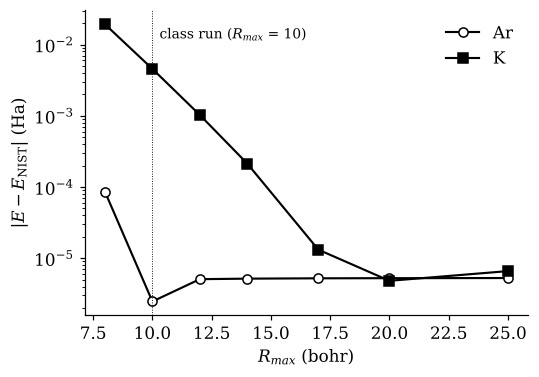

In [26]:
Rmax_list = [8, 10, 12, 14, 17, 20, 25]
h = 20/2**14                                   # keep the grid spacing fixed
dE = {'Ar': [], 'K': []}
for Rm in Rmax_list:
    for s, Z in [('Ar', 18), ('K', 19)]:
        a = lda_atom(Z, CONFIG[s], Rmax=Rm, N=int(round(Rm/h)) + 1)
        dE[s].append(a['Etot'] - E_NIST[s])

fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.semilogy(Rmax_list, np.abs(dE['Ar']), 'o-', color='k', mfc='white', label='Ar')
ax.semilogy(Rmax_list, np.abs(dE['K']), 's-', color='k', label='K')
ax.axvline(10, color='k', lw=0.6, ls=':')
ax.text(10.3, 1.2e-2, r'class run ($R_{max}$ = 10)', fontsize=9)
ax.set_xlabel(r'$R_{max}$ (bohr)')
ax.set_ylabel(r'$|E - E_{\rm NIST}|$ (Ha)')
ax.legend()
plt.show()

## Example 2: H to Kr, neutral atoms and cations

Each atom is run in its NIST ground-state configuration, and each cation is
started from the converged potential of the neutral atom. The first ionization
energy follows from two total energies ("$\Delta$SCF"):
$$I = E(X^+) - E(X).$$
The 3d metals (Sc–Zn) use the mixing parameter $\alpha = 0.3$. With
$\alpha=0.5$ the SCF loop does not converge for Cr, Ni$^+$, Cu and Cu$^+$
(Example 10). This cell takes a few minutes.

In [27]:
atoms, ions = {}, {}
t0 = time.time()
print(' Z  atom configuration         E_LDA (Ha)  E-E_NIST (mHa)  I (eV)  iterations')
for Z in range(1, 37):
    s = SYMBOL[Z]
    mix = 0.3 if 21 <= Z <= 30 else 0.5
    atoms[s] = lda_atom(Z, CONFIG[s], mix=mix)
    if Z == 1:
        ions[s] = dict(Etot=0.0)                 # H+ has no electrons
    else:
        ions[s] = lda_atom(Z, CONFIG[s + '+'], mix=mix, Uks0=atoms[s]['Uks'])
    assert atoms[s]['converged'] and (Z == 1 or ions[s]['converged'])
    I = (ions[s]['Etot'] - atoms[s]['Etot'])*Ha_eV
    print(f"{Z:2d}  {s:3s}  {CONFIG[s]:20s}{atoms[s]['Etot']:14.6f}"
          f"{1e3*(atoms[s]['Etot'] - E_NIST[s]):12.3f}{I:10.3f}{len(atoms[s]['hist']):8d}")

for s, Z in [('Xe', 54), ('Rn', 86)]:            # heavy noble gases, finer grid
    atoms[s] = lda_atom(Z, CONFIG[s], N=2**15+1)
    print(f"{Z:2d}  {s:3s}  {CONFIG[s]:20s}{atoms[s]['Etot']:14.6f}"
          f"{1e3*(atoms[s]['Etot'] - E_NIST[s]):12.3f}{'':10s}{len(atoms[s]['hist']):8d}")
print(f'{time.time() - t0:.0f} s')

 Z  atom configuration         E_LDA (Ha)  E-E_NIST (mHa)  I (eV)  iterations


 1  H    1s^1                     -0.445670       0.001    12.127      17


 2  He   1s^2                     -2.834836       0.000    26.493      14


 3  Li   [He] 2s^1                -7.335195       0.000     5.235      19


 4  Be   [He] 2s^2               -14.447210      -0.001     9.511      17


 5  B    [He] 2s^2 2p^1          -24.344198      -0.000     8.325      22


... (29 outputs left out)

35  Br   [Ar] 3d^10 4s^2 4p^5  -2570.620856      -0.156    12.730      30


36  Kr   [Ar] 3d^10 4s^2 4p^6  -2750.148118      -0.178    14.458      32


54  Xe   [Kr] 4d^10 5s^2 5p^6  -7228.856227      -0.120                35


86  Rn   [Xe] 4f^14 5d^10 6s^2 6p^6 -21861.347697      -0.828                37
248 s


## Example 3: shell structure in the density

On a logarithmic $r$ axis the natural quantity is
$dN/d\ln r = 4\pi r^3\rho(r)$: the area under a curve is its number of
electrons. Black: the total density. Colors: the contribution of each principal
shell $n$, summed over $l$; the numbers are the electrons in each shell. The
outer shells give separate maxima. The inner shells are compressed toward the
nucleus, overlap with their neighbors, and appear only as shoulders.

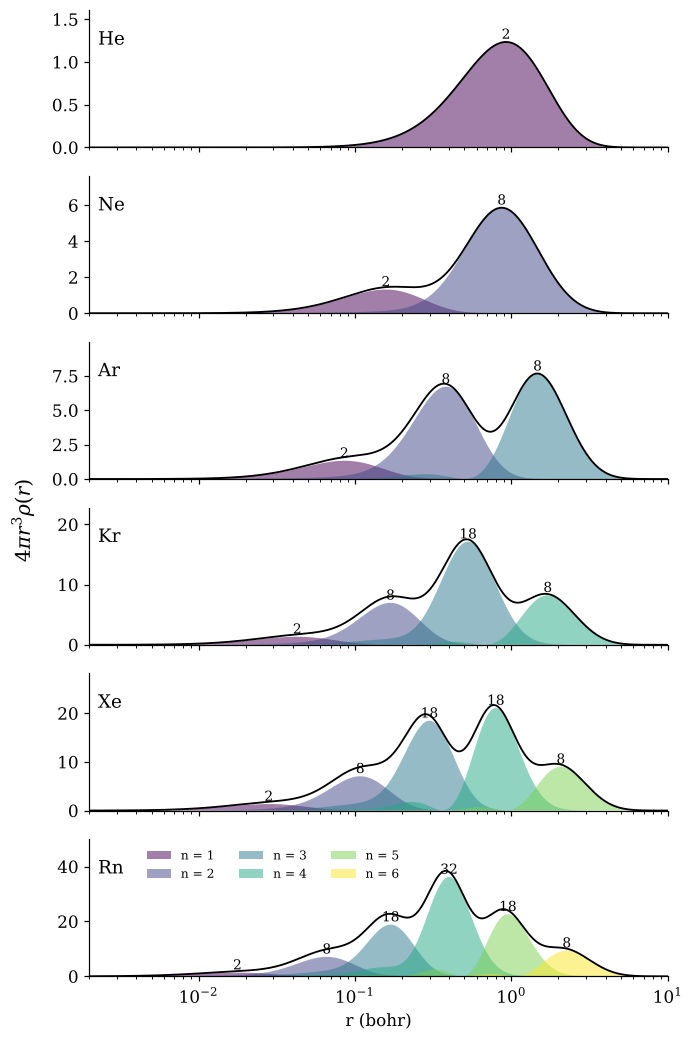

In [28]:
fig, axes = plt.subplots(6, 1, figsize=(6.4, 9.6), sharex=True)
shell_color = [plt.get_cmap('viridis')(k/5) for k in range(6)]
for ax, s in zip(axes, ['He', 'Ne', 'Ar', 'Kr', 'Xe', 'Rn']):
    a = atoms[s]
    R = a['R']
    for n in range(1, max(nn for nn, l in a['occ']) + 1):
        sub = [(l, q) for (nn, l), q in a['occ'].items() if nn == n]
        Dn = sum(q*R*orbital(a, n, l)**2 for l, q in sub)      # 4 pi r^3 rho_n
        ax.fill_between(R, Dn, color=shell_color[n-1], alpha=0.5, lw=0,
                        label=f'n = {n}')
        ip = np.argmax(Dn)
        ax.text(R[ip], Dn[ip], f'{sum(q for l, q in sub):.0f}',
                ha='center', va='bottom', fontsize=9)
    D = 4*np.pi*R**3*a['rho']
    ax.plot(R, D, 'k', lw=1.2)
    ax.set_xscale('log')
    ax.set_xlim(2e-3, 10)
    ax.set_ylim(0, 1.3*D.max())
    ax.text(0.015, 0.75, s, transform=ax.transAxes, fontsize=12)
axes[-1].legend(loc='upper left', bbox_to_anchor=(0.08, 1.0), ncol=3, fontsize=8)
axes[-1].set_xlabel('r (bohr)')
fig.supylabel(r'$4\pi r^3\rho(r)$')
plt.tight_layout()
plt.show()

## Example 4: Kohn–Sham orbitals of Kr in real space

Cross-sections $y=0$ (horizontal $x$, vertical $z$) of
$\psi_{nl0}(\mathbf r) = R_{nl}(r)\,Y_{l0}(\theta)$ from the converged Kr potential. The color shows $r\,\psi$ so that the outer lobes
are visible; red and blue are the two signs. An orbital has $n-l-1$ radial
nodes (circles) and $l$ angular nodes (cones; lines in the cut). Each panel has
its own scale: $\langle r\rangle$ grows from 0.04 bohr (1s) to 2 bohr (4p).

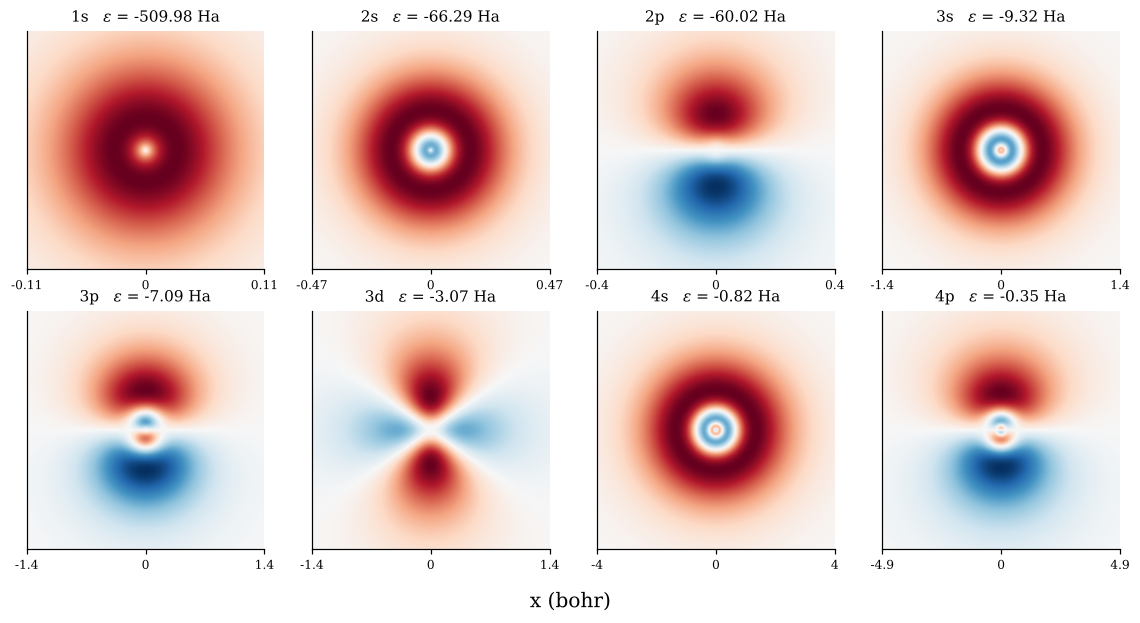

In [29]:
a = atoms['Kr']
shells = [(1, 0), (2, 0), (2, 1), (3, 0), (3, 1), (3, 2), (4, 0), (4, 1)]
fig, axes = plt.subplots(2, 4, figsize=(10.5, 5.6))
for ax, (n, l) in zip(axes.flat, shells):
    u = orbital(a, n, l)
    L = 2.5*mean_r(a, n, l)
    x = np.linspace(-L, L, 401)
    X, Y = np.meshgrid(x, x)
    r = np.hypot(X, Y)
    cos_t = Y/np.maximum(r, 1e-12)
    rpsi = np.interp(r, a['R'], u)*np.sqrt((2*l + 1)/(4*np.pi))*eval_legendre(l, cos_t)
    vmax = np.abs(rpsi).max()
    ax.imshow(rpsi, extent=[-L, L, -L, L], origin='lower', cmap='RdBu_r',
              vmin=-vmax, vmax=vmax)
    ax.set_title(f"{n}{LNAME[l]}   $\\varepsilon$ = {a['eps'][(n, l)]:.2f} Ha", fontsize=10)
    ax.set_xticks([-L, 0, L], [f'{-L:.2g}', '0', f'{L:.2g}'])
    ax.set_yticks([])
    ax.tick_params(labelsize=8)
fig.supxlabel('x (bohr)')
plt.tight_layout()
plt.show()

## Example 5: screening of the nucleus

Write the Kohn–Sham potential as $V_{KS}(r) = -Z_{\rm eff}(r)/r$ (Hartree units),
so $Z_{\rm eff}(r) = -U_{KS}(r)/2$. Near the nucleus an electron sees the full
charge $Z$; at larger $r$ the electrons inside screen it. The dashed curve
keeps only the nucleus and the Hartree term, $Z - U_H(r)/2$. The logarithmic
axis shows the tail.

Far outside, an electron should see the ion left behind: $Z_{\rm eff}\to 1$.
In LDA, $V_{xc}$ follows the density and decays exponentially, so
$Z_{\rm eff}\to 0$. The outermost electrons are therefore too weakly bound:
$-\varepsilon_{\rm HOMO}$ underestimates the ionization energy (Example 7).

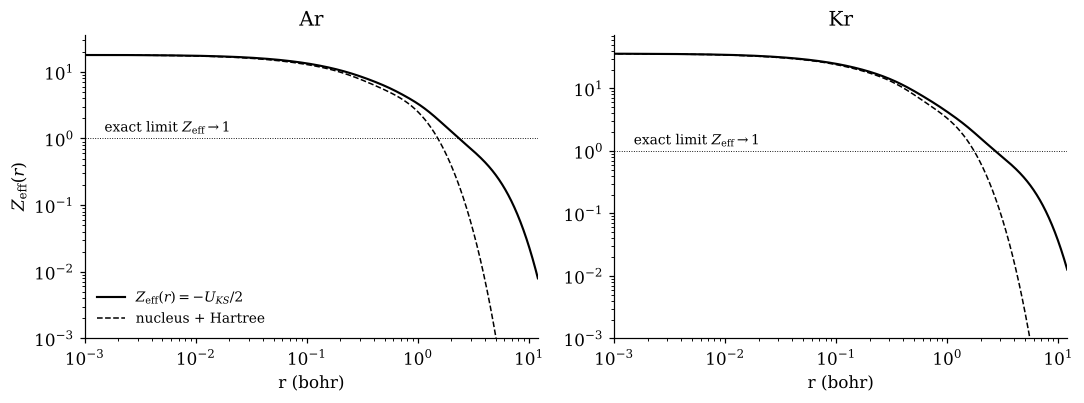

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, s in zip(axes, ['Ar', 'Kr']):
    a = atoms[s]
    R = a['R']
    ax.plot(R, -a['Uks']/2, 'k', label=r'$Z_{\rm eff}(r) = -U_{KS}/2$')
    ax.plot(R, a['Z'] - a['UH']/2, 'k--', lw=1, label=r'nucleus + Hartree')
    ax.axhline(1, color='k', lw=0.6, ls=':')
    ax.text(1.5e-3, 1.25, r'exact limit $Z_{\rm eff}\to 1$', fontsize=9)
    ax.set_xscale('log')
    ax.set_xlim(1e-3, 12)
    ax.set_yscale('log')
    ax.set_ylim(1e-3, 2*a['Z'])
    ax.set_xlabel('r (bohr)')
    ax.set_title(s)
axes[0].set_ylabel(r'$Z_{\rm eff}(r)$')
axes[0].legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.show()

## Example 6: orbital energies across the periodic table

Left: $-\varepsilon_{nl}$ of the occupied orbitals for H–Kr on a logarithmic
scale. Core levels grow roughly as $Z^2$; a new shell starts at Li, Na and K.
Right: 4s and 3d across K–Zn (open symbol: bound but empty). In K the 3d level
is not bound; in Ca it is empty and above 4s, so 4s fills first. From Sc on,
the 3d level falls quickly and passes below 4s at Ti. In Cr and Cu one 4s
electron moves to 3d ($3d^5 4s^1$, $3d^{10} 4s^1$) and the 3d level rises again.

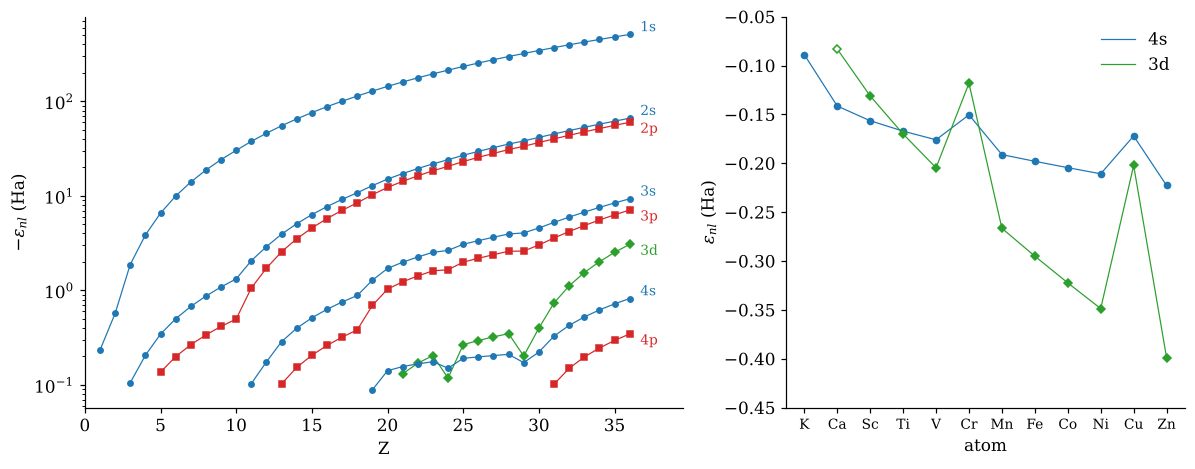

In [31]:
Zs = np.arange(1, 37)
lstyle = {0: ('o', 'C0'), 1: ('s', 'C3'), 2: ('D', 'C2')}
orbs = [(1, 0), (2, 0), (2, 1), (3, 0), (3, 1), (3, 2), (4, 0), (4, 1)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4),
                               gridspec_kw=dict(width_ratios=[1.5, 1]))
for (n, l) in orbs:
    m, c = lstyle[l]
    pts = [(Z, -atoms[SYMBOL[Z]]['eps'][(n, l)]) for Z in Zs
           if (n, l) in atoms[SYMBOL[Z]]['occ']]
    Zo, Eo = map(np.array, zip(*pts))
    ax1.plot(Zo, Eo, m + '-', color=c, ms=3.5, lw=0.8)
    ax1.text(Zo[-1] + 0.7, Eo[-1], f'{n}{LNAME[l]}', color=c, fontsize=9,
             va='bottom' if l == 0 else 'top')
ax1.set_yscale('log')
ax1.set_xlim(0, 39.5)
ax1.set_xlabel('Z')
ax1.set_ylabel(r'$-\varepsilon_{nl}$ (Ha)')

Zr = range(19, 31)
for (n, l), lab in [((4, 0), '4s'), ((3, 2), '3d')]:
    m, c = lstyle[l]
    pts = [(Z, atoms[SYMBOL[Z]]['eps'][(n, l)], (n, l) in atoms[SYMBOL[Z]]['occ'])
           for Z in Zr if (n, l) in atoms[SYMBOL[Z]]['eps']]
    Zo, Eo, occ = map(np.array, zip(*pts))
    ax2.plot(Zo, Eo, color=c, lw=0.8, label=lab)
    ax2.plot(Zo[occ], Eo[occ], m, color=c, ms=4)
    ax2.plot(Zo[~occ], Eo[~occ], m, color=c, ms=4, mfc='white')
ax2.set_xticks(list(Zr), [SYMBOL[Z] for Z in Zr], fontsize=9)
ax2.set_ylim(-0.45, -0.05)
ax2.set_xlabel('atom')
ax2.set_ylabel(r'$\varepsilon_{nl}$ (Ha)')
ax2.legend()
plt.tight_layout()
plt.show()

## Example 7: ionization energy and size

Top: first ionization energy from $\Delta$SCF, from $-\varepsilon_{\rm HOMO}$, and
from experiment. The $\Delta$SCF values follow the experimental periodicity:
maxima at the noble gases, minima at the alkali metals, the dips at B, Al and
Ga where a new p shell starts. Two misses:

* $-\varepsilon_{\rm HOMO}$ is 25–55% too small, because of the wrong
  asymptotic potential (Example 5).
* Experiment drops from N to O (and from P to S). With 3 p electrons all spins
  are parallel (Hund's rule); the 4th must pair. Our code is spin-unpolarized,
  so it cannot see this.

Bottom: $\langle r\rangle$ of the outermost occupied orbital. Atoms are large at
the start of a row and shrink across it as $Z$ grows.

mean |error| vs experiment: Delta-SCF 0.76 eV, -eps_HOMO 3.95 eV
-eps_HOMO / I_exp: 0.45 to 0.75


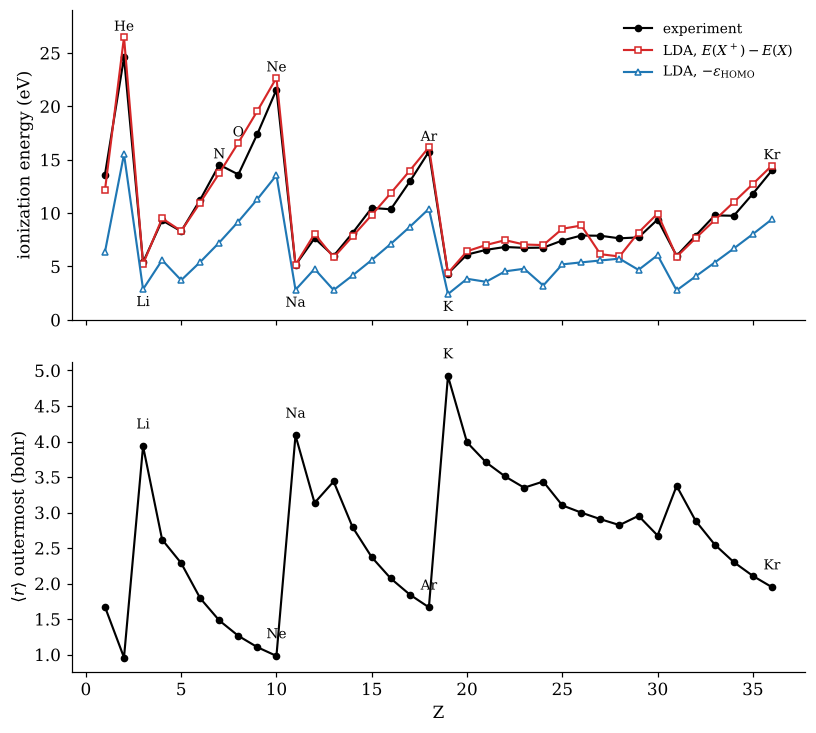

In [32]:
syms = [SYMBOL[Z] for Z in Zs]
I_lda = np.array([(ions[s]['Etot'] - atoms[s]['Etot'])*Ha_eV for s in syms])
I_homo = np.array([-atoms[s]['eps'][homo(atoms[s])]*Ha_eV for s in syms])
I_exp = np.array([IE_EXP[Z] for Z in Zs])
r_out = np.array([max(mean_r(atoms[s], n, l) for (n, l) in atoms[s]['occ']) for s in syms])

print(f'mean |error| vs experiment: Delta-SCF {np.mean(np.abs(I_lda - I_exp)):.2f} eV, '
      f'-eps_HOMO {np.mean(np.abs(I_homo - I_exp)):.2f} eV')
print(f'-eps_HOMO / I_exp: {np.min(I_homo/I_exp):.2f} to {np.max(I_homo/I_exp):.2f}')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.5, 6.8), sharex=True)
ax1.plot(Zs, I_exp, 'o-', color='k', ms=4, label='experiment')
ax1.plot(Zs, I_lda, 's-', color='C3', ms=4, mfc='white', label=r'LDA, $E(X^+)-E(X)$')
ax1.plot(Zs, I_homo, '^-', color='C0', ms=4, mfc='white', label=r'LDA, $-\varepsilon_{\rm HOMO}$')
for Z in [2, 10, 18, 36, 7, 8]:
    ax1.text(Z, max(I_exp[Z-1], I_lda[Z-1]) + 0.6, SYMBOL[Z], ha='center', fontsize=9)
for Z in [3, 11, 19]:
    ax1.text(Z, I_homo[Z-1] - 0.6, SYMBOL[Z], ha='center', va='top', fontsize=9)
ax1.set_ylabel('ionization energy (eV)')
ax1.set_ylim(0, 29)
ax1.legend(loc='upper right', fontsize=9)
ax2.plot(Zs, r_out, 'o-', color='k', ms=4)
for Z in [3, 11, 19, 10, 18, 36]:
    ax2.text(Z, r_out[Z-1] + 0.25, SYMBOL[Z], ha='center', fontsize=9)
ax2.set_xlabel('Z')
ax2.set_ylabel(r'$\langle r\rangle$ outermost (bohr)')
plt.tight_layout()
plt.show()

## Example 8: periodic table maps

The same two quantities on the periodic table, plus the error of the
$\Delta$SCF ionization energy. The sign of the error follows the electron spins,
which our spin-unpolarized code ignores. Unpaired electrons with parallel spins
lower the energy (exchange). When ionization increases the number of unpaired
electrons, the ion gains more of this energy than the atom, and the LDA value
is too high: He, Ne (0 → 1), O (2 → 3), F (1 → 2), Mn, Fe (red). When it
decreases the number, the LDA value is too low: H (1 → 0), N (3 → 2),
Co and Ni (blue). Cr and Cu do not follow the rule; for Na, K and B the error
is below 0.05 eV.

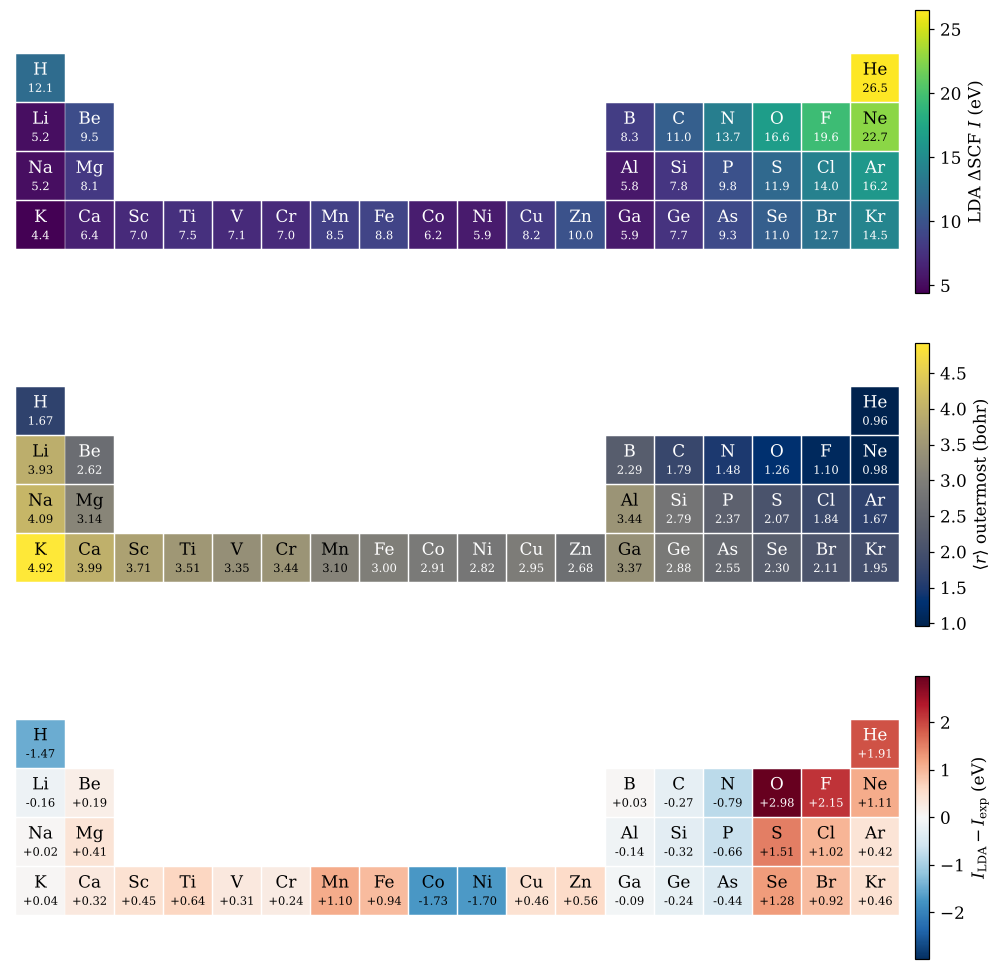

In [33]:
def table_position(Z):
    if Z <= 2:
        return 1, (1 if Z == 1 else 18)
    if Z <= 18:
        row, k = (2, Z - 2) if Z <= 10 else (3, Z - 10)
        return row, (k if k <= 2 else k + 10)
    return 4, Z - 18


def table_map(ax, values, fmt, cmap, norm, label):
    for Z, v in zip(Zs, values):
        row, col = table_position(Z)
        c = plt.get_cmap(cmap)(norm(v))
        ax.add_patch(plt.Rectangle((col - 0.47, -row - 0.47), 0.94, 0.94, color=c))
        tc = 'white' if sum(c[:3])/3 < 0.5 else 'black'
        ax.text(col, -row + 0.16, SYMBOL[Z], ha='center', va='center', fontsize=11, color=tc)
        ax.text(col, -row - 0.22, fmt.format(v), ha='center', va='center', fontsize=7.5, color=tc)
    ax.set_xlim(0.4, 18.6)
    ax.set_ylim(-4.6, -0.4)
    ax.set_aspect('equal')
    ax.axis('off')
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    plt.colorbar(sm, ax=ax, shrink=0.8, pad=0.01, label=label)


fig, axes = plt.subplots(3, 1, figsize=(10, 9.6))
table_map(axes[0], I_lda, '{:.1f}', 'viridis', plt.Normalize(I_lda.min(), I_lda.max()),
          r'LDA $\Delta$SCF $I$ (eV)')
table_map(axes[1], r_out, '{:.2f}', 'cividis', plt.Normalize(r_out.min(), r_out.max()),
          r'$\langle r\rangle$ outermost (bohr)')
err = I_lda - I_exp
emax = np.abs(err).max()
table_map(axes[2], err, '{:+.2f}', 'RdBu_r', plt.Normalize(-emax, emax),
          r'$I_{\rm LDA} - I_{\rm exp}$ (eV)')
plt.tight_layout()
plt.show()

## Example 9: the Thomas–Fermi limit

For large $Z$ the total energy approaches the Thomas–Fermi law
$E \approx -0.7687\,Z^{7/3}$ Ha, with the Scott ($+Z^2/2$) and Schwinger
($-0.2699\,Z^{5/3}$) corrections. Plotting $-E/Z^{7/3}$ against $Z^{-1/3}$
turns this into a parabola that ends at 0.7687 for $Z\to\infty$. The points are
our LDA total energies from H to Rn.

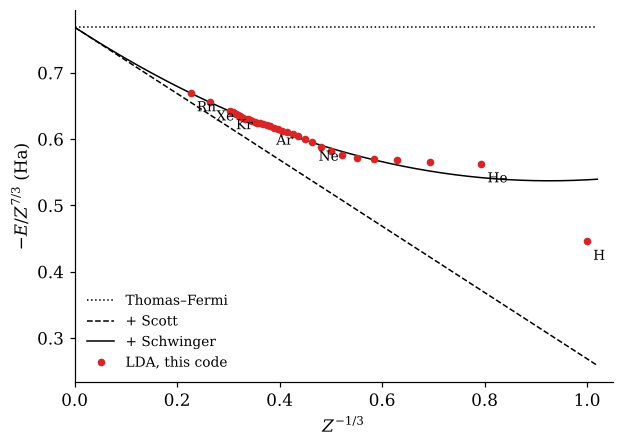

In [34]:
Zp = np.array([atoms[s]['Z'] for s in atoms])
Ep = np.array([atoms[s]['Etot'] for s in atoms])
x = Zp**(-1/3)
y = -Ep/Zp**(7/3)
xx = np.linspace(0, 1.02, 200)

fig, ax = plt.subplots(figsize=(5.8, 4.2))
ax.plot(xx, 0.768745 + 0*xx, 'k:', lw=1, label='Thomas–Fermi')
ax.plot(xx, 0.768745 - 0.5*xx, 'k--', lw=1, label='+ Scott')
ax.plot(xx, 0.768745 - 0.5*xx + 0.269900*xx**2, 'k-', lw=1, label='+ Schwinger')
ax.plot(x, y, 'o', color='C3', ms=4, label='LDA, this code')
for s in ['H', 'He', 'Ne', 'Ar', 'Kr', 'Xe', 'Rn']:
    Z = atoms[s]['Z']
    ax.annotate(s, (Z**(-1/3), -atoms[s]['Etot']/Z**(7/3)), xytext=(4, -12),
                textcoords='offset points', fontsize=9)
ax.set_xlim(0, 1.05)
ax.set_xlabel(r'$Z^{-1/3}$')
ax.set_ylabel(r'$-E/Z^{7/3}$ (Ha)')
ax.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.show()

## Example 10: density mixing and charge sloshing

Linear mixing $\rho_{in}^{(i+1)} = \alpha\rho_{out}^{(i)} + (1-\alpha)\rho_{in}^{(i)}$
converges only if $\alpha$ is small enough. For Ar, $\alpha$ up to 0.8 works,
and 0.5 is fastest. For Cu with $\alpha=0.5$ the compact 3d shell over-reacts:
too much 3d charge raises the potential, which pushes the charge out in the
next step. The loop falls into a two-step oscillation and never converges; the
3d eigenvalue jumps between two values (right). With $\alpha=0.5$ the same
happens for Cr, Ni$^+$ and Cu$^+$. A smaller $\alpha$ fixes it at the cost of
more iterations. Better mixing schemes (Anderson, Broyden) use the history of
previous iterations.

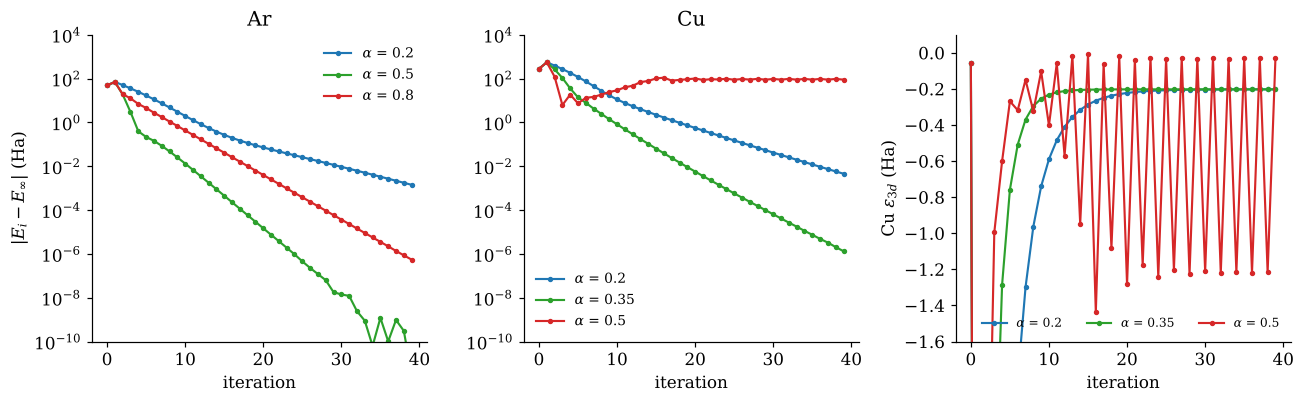

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
runs = {}
for ax, (s, mixes) in zip(axes[:2], [('Ar', [0.2, 0.5, 0.8]), ('Cu', [0.2, 0.35, 0.5])]):
    Z = atoms[s]['Z']
    Eref = lda_atom(Z, CONFIG[s], mix=0.3, Etol=1e-10)['Etot']
    for mix, c in zip(mixes, ['C0', 'C2', 'C3']):
        r = lda_atom(Z, CONFIG[s], mix=mix, Etol=1e-10, maxiter=40)
        runs[(s, mix)] = r
        ax.semilogy(np.abs(r['hist'] - Eref) + 1e-12, 'o-', ms=2.5, color=c,
                    label=rf'$\alpha$ = {mix}')
    ax.set_xlabel('iteration')
    ax.set_title(s)
    ax.set_ylim(1e-10, 1e4)
    ax.legend(fontsize=9)
axes[0].set_ylabel(r'$|E_i - E_\infty|$ (Ha)')

for mix, c in zip([0.2, 0.35, 0.5], ['C0', 'C2', 'C3']):
    e3d = [e[(3, 2)] for e in runs[('Cu', mix)]['eps_hist'] if (3, 2) in e]
    axes[2].plot(e3d, 'o-', ms=2.5, color=c, label=rf'$\alpha$ = {mix}')
axes[2].set_xlabel('iteration')
axes[2].set_ylim(-1.6, 0.1)
axes[2].set_ylabel(r'Cu $\varepsilon_{3d}$ (Ha)')
axes[2].legend(fontsize=8, ncol=3, loc='lower right')
plt.tight_layout()
plt.show()